# CA4 - Telecom Customer Churn Classification

#### Gr 30: Sondre Aasheim & Zuzanna Magdalena Smolinska

### Imports

In [2]:
import numpy as np                      # for numerical operations
import pandas as pd                     # for reading the csv files and working with dataframes
import matplotlib.pyplot as plt         # for basic plotting
import seaborn as sns                   # for more advanced plotting

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, confusion_matrix, ConfusionMatrixDisplay

from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

RULES AND CONTEXT OF THE COMPETITION

1. The general workflow is similar to that of CA3. As opposed to CA3, however, you are now expected to use cross-validation instead of multiple train/validation splits. You can use the scikit-learn implementations for cross-validation.

2. You have access to a range of classifiers, kernels, and L1/L2-regularisation covered in DAT200. These can be combined freely. You can also use the ensemble models presented in the lectures. Use the corresponding scikit-learn implementations.

3. Classifier selection and hyperparameter tuning are the core of this exercise. You are expected to make use of all of the following components:

   - Hyperparameter tuning (using scikit-learn tools from Chapter 6)
   - Scikit-learn Pipelines
   - Cross-validation
   - Some form of dimension reduction (e.g. PCA or SFS)
   - A confusion matrix for your final classifier, using a 60/40 train-test split on the entire training dataset
   - Macro-averaged F1-score as the primary evaluation metric (other metrics are encouraged too)

   You must build at least two pipelines combining preprocessing with a classifier. One pipeline must use a kernel, one must use regularisation, and at least one must include a dimension reduction step.

4. You may try other models. If your best-performing Kaggle submission is not one of the two mandatory pipelines, also provide the code for training, tuning, and prediction for that classifier.

5. You may engineer new features if you wish.

6. If you are unsure how to structure your notebook, follow these steps:
   Imports → Read the data → Data exploration & visualisation → Data cleaning → Data exploration & visualisation after cleaning → Preprocessing → Evaluating models/hyperparameters (cross-validation) → Kaggle submission.

━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━


# Read the data

In [9]:
# reading the data (both files must be in the same folder as this notebook)
telecom_customer_train = pd.read_csv("trainCA4DAT200.csv")
telecom_customer_test = pd.read_csv("testCA4DAT200.csv")


DATA DESCRIPTION

The dataset contains information about the customers of a mobile phone operator. Each row is one customer. The features are:

   - CustomerId – unique ID of the customer (not a feature for modelling)
   - State – US state where the customer lives (two-letter code)
   - AccountLength – how long the customer has had an account
   - AreaCode – telephone area code of the customer
   - InternationalPlan – whether the customer has an international calling plan (yes/no)
   - VoiceMailPlan – whether the customer has a voice mail plan (yes/no)
   - NumVoiceMailMessages – number of voice mail messages
   - DayMinutes, DayCalls, DayCharge – total minutes, number of calls and total charge for daytime calls
   - EveMinutes, EveCalls, EveCharge – the same for evening calls
   - NightMinutes, NightCalls, NightCharge – the same for night calls
   - IntlMinutes, IntlCalls, IntlCharge – the same for international calls
   - CustomerServiceCalls – number of calls the customer has made to customer service

Target variable: Churn
   - 0 = customer stays
   - 1 = customer leaves the company

━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━

# Data exploration & visualisation

In [21]:
# printing the training data to get a look at the size
print("Train shape:", telecom_customer_train.shape)
print("Test shape: ", telecom_customer_test.shape)

# To get a look at the dataframe  
telecom_customer_train.head()

Train shape: (3500, 21)
Test shape:  (1500, 20)


,CustomerId,State,AccountLength,AreaCode,InternationalPlan,VoiceMailPlan,NumVoiceMailMessages,DayMinutes,DayCalls,DayCharge,...,EveCalls,EveCharge,NightMinutes,NightCalls,NightCharge,IntlMinutes,IntlCalls,IntlCharge,CustomerServiceCalls,Churn
0,952920,NJ,87,510,no,no,0,223.2,109,37.94,...,86,10.84,289.3,83,13.02,14.5,4,3.92,3,0
1,895150,RI,114,510,no,yes,28,225.8,94,38.39,...,117,16.41,232.4,100,10.46,8.4,9,2.27,4,0
2,636987,ND,55,415,no,no,0,180.1,77,30.62,...,98,20.02,169.4,104,7.62,11.1,2,3.00,0,0
3,538188,DC,100,510,yes,no,0,68.5,110,11.65,...,115,28.65,205.2,99,9.23,12.1,9,3.27,0,0
4,947531,AL,74,408,no,yes,46,277.7,109,47.21,...,114,22.95,165.3,82,7.44,10.4,2,2.81,1,0


In [ ]:
# Another display to get a overall view over the data, had to keep it seperate from the "head" comand
telecom_customer_train.describe()


,CustomerId,AccountLength,AreaCode,NumVoiceMailMessages,DayMinutes,DayCalls,DayCharge,EveMinutes,EveCalls,EveCharge,NightMinutes,NightCalls,NightCharge,IntlMinutes,IntlCalls,IntlCharge,CustomerServiceCalls,Churn
count,3500.000000,3500.000000,3500.000000,3500.000000,3500.000000,3500.000000,3500.000000,3500.000000,3500.000000,3500.000000,3500.000000,3500.000000,3500.000000,3500.000000,3500.000000,3500.000000,3500.000000,3500.000000
mean,545925.360857,99.996571,436.915429,8.112000,180.292429,100.016286,30.650306,200.763000,100.178000,17.065066,199.984857,99.669714,8.999397,10.297714,4.417143,2.780829,1.567714,0.141429
std,261478.546087,39.471509,42.169180,13.728371,53.764503,19.852587,9.139923,50.561814,19.800506,4.297740,50.132089,20.064302,2.256017,2.719716,2.456653,0.734263,1.298641,0.348513
min,101267.000000,1.000000,408.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,322381.000000,73.000000,415.000000,0.000000,143.700000,87.000000,24.430000,165.900000,87.000000,14.100000,166.700000,86.000000,7.500000,8.600000,3.000000,2.320000,1.000000,0.000000
50%,536375.500000,100.000000,415.000000,0.000000,179.700000,100.000000,30.550000,201.050000,100.000000,17.090000,199.700000,100.000000,8.990000,10.400000,4.000000,2.810000,1.000000,0.000000
75%,775246.750000,126.000000,415.000000,19.000000,216.525000,113.000000,36.812500,235.225000,113.000000,19.992500,233.625000,113.000000,10.512500,12.000000,6.000000,3.240000,2.000000,0.000000
max,999391.000000,243.000000,510.000000,52.000000,351.500000,163.000000,59.760000,361.800000,170.000000,30.750000,395.000000,175.000000,17.770000,20.000000,19.000000,5.400000,9.000000,1.000000


In [24]:
# To see how many customers leaves the company 
telecom_customer_train["Churn"].value_counts()[1]


np.int64(495)

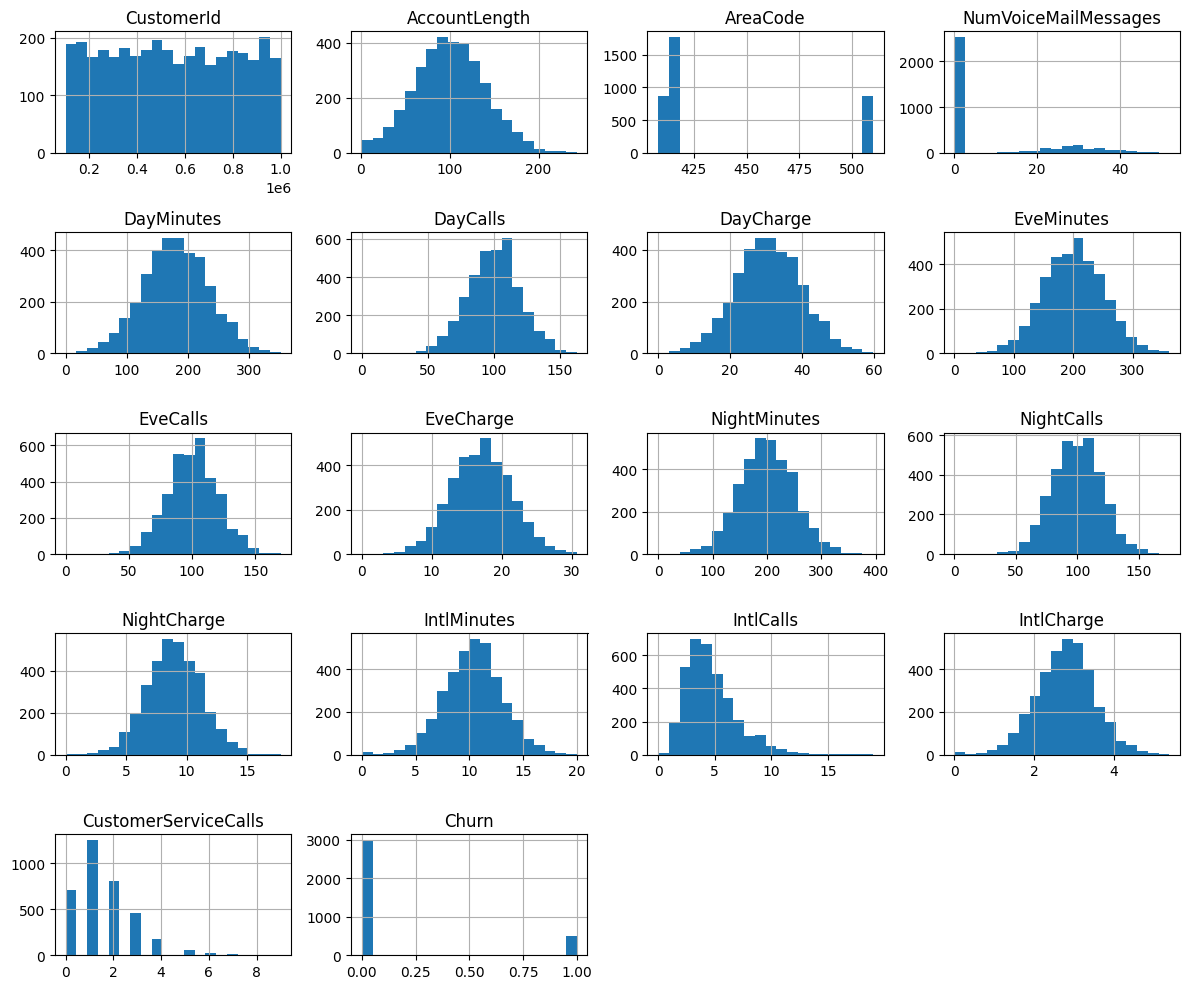

In [27]:
# Some graphs of the various values 
telecom_customer_train.hist(figsize=(12, 10), bins=20)
plt.tight_layout()
plt.show()

# Data cleaning

# Data exploration & visualisation after cleaning 

# Preprocessing 

# Evaluating models/hyperparameters (cross-validation)

# Kaggle submission



BACKGROUND

You have been hired by a mobile phone operator in the United States. The company is experiencing customer churn, where customers cancel their subscription and move to a competing operator. Retaining existing customers is often significantly cheaper than acquiring new ones.

Your task is to develop a machine learning model capable of predicting whether a customer will leave the company based on information about their subscription plan and phone usage. Accurate churn prediction models allow companies to identify customers who may leave and take proactive measures to retain them.

churn.png

━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━


KAGGLE COMPETITION

You will participate in an in-class Kaggle competition where you will compete with fellow students on how well your model predicts the test data.

1. Link to our in-class competition on Kaggle:
   DAT200 CA4 H2026: https://www.kaggle.com/competitions/dat-200-ca-4-h-2026/overview 

2. Enrolment link (do not forward this link to anyone outside DAT200):
   https://www.kaggle.com/t/57bfce3eeeb14253a4a1e02ce6e2a15f 

3. On the Data tab of the competition you will find three files:
   - trainCA4DAT200.csv – 3,500 customers, including the target column Churn
   - testCA4DAT200.csv – 1,500 customers, without the target column
   - sample_submissionCA4DAT200.csv – shows the required format of your submission

4. Notebook template: You can use the notebook template from the last compulsory assignment (CA3) to build your classification pipeline, or start from scratch. Note that CA3 used repeated train/validation splits and accuracy. In CA4 you must use cross-validation and macro F1 instead, so update the template's headings and code accordingly.

━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━


IMPORTANT NOTES

- It is your responsibility to upload your submission before the deadline to both Canvas and Kaggle. Plan for possible technical difficulties. You may submit multiple times — only the final submission counts.
- Complete the assignment as a group.
- If you copy a larger piece of code (multiple lines or a complex expression), cite the source with a link, mark the copied section, and explain what it does in your own words.
- Train and evaluate your models only on the data provided in this competition. Using any other version of this data, or labels from outside the competition, is not allowed and counts as cheating.
- Review the CA rules on the course pages. You must pass all CAs to be admitted to the exam.

━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━

DELIVERABLES / SUBMISSION

To have the compulsory assignment approved you need to deliver the following:

1. Data exploration and visualisation of the data is mandatory. Use several techniques to explore the data effectively.
2. Your name must appear on the leaderboard of our in-class Kaggle competition, meaning you must submit at least one prediction.
3. We expect you to beat the benchmark (named BEAT ME) on the public leaderboard.
   Evaluation metric: F1 macro score.
4. Submit the following files:
   - Jupyter notebook (.ipynb)
   - PDF export of the notebook
   - Python code (.py)
   Your submission must include a confusion matrix.
5. If you use an alias on Kaggle, provide both your alias and real name at the beginning of the notebook.